In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import skew, kurtosis, zscore
from sklearn.feature_selection import VarianceThreshold
import missingno as msno
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity

In [21]:
file_path = 'ISTAT_census_variables_2011.csv' 
df = pd.read_csv(file_path)

In [22]:
print("\nDataset Shape:", df.shape)


Dataset Shape: (110, 135)


In [23]:
print("\nFirst 5 Rows:")
df.head()



First 5 Rows:


,PROVINCIA,P1,P2,P3,P4,P5,P6,P7,P8,P9,...,E18,E19,E20,E21,E22,E23,E24,E25,E26,E27
0,Alessandria,427229,204983,222246,158222,198253,11481,44582,14691,85839,...,82121,27855,7197,84634,23155,10813,5564,2523,1896,280402
1,Asti,217573,105370,112203,82119,102538,5404,20767,6745,44773,...,49604,11716,3039,48074,12510,4775,2083,1194,786,134452
2,Biella,182192,86821,95371,69188,82431,5266,18474,6833,37017,...,25523,19595,5795,35030,11310,4776,2066,974,581,112204
3,Cuneo,586378,287786,298592,231452,276983,12473,49417,16053,127243,...,113200,43780,10393,106446,41341,18356,8181,3449,2278,402507
4,Novara,365559,176361,189198,143302,170741,9351,31811,10354,76929,...,40028,25384,5773,39561,22413,10224,4404,2272,1148,199727


In [24]:
print("\nColumn Names:")
df.columns.tolist()


Column Names:


['PROVINCIA',
 'P1',
 'P2',
 'P3',
 'P4',
 'P5',
 'P6',
 'P7',
 'P8',
 'P9',
 'P10',
 'P11',
 'P12',
 'P13',
 'P14',
 'P15',
 'P16',
 'P17',
 'P18',
 'P19',
 'P20',
 'P21',
 'P22',
 'P23',
 'P24',
 'P25',
 'P26',
 'P27',
 'P28',
 'P29',
 'P30',
 'P31',
 'P32',
 'P33',
 'P34',
 'P35',
 'P36',
 'P37',
 'P38',
 'P39',
 'P40',
 'P41',
 'P42',
 'P43',
 'P44',
 'P45',
 'P46',
 'P47',
 'P48',
 'P49',
 'P50',
 'P51',
 'P52',
 'P53',
 'P54',
 'P55',
 'P56',
 'P57',
 'P58',
 'P59',
 'P60',
 'P61',
 'P62',
 'P64',
 'P65',
 'P66',
 'P128',
 'P129',
 'P130',
 'P131',
 'P132',
 'P135',
 'P136',
 'P137',
 'P138',
 'P139',
 'P140',
 'ST1',
 'ST2',
 'ST3',
 'ST4',
 'ST5',
 'ST6',
 'ST7',
 'ST8',
 'ST9',
 'ST10',
 'ST11',
 'ST12',
 'ST13',
 'ST14',
 'ST15',
 'A2',
 'A3',
 'A5',
 'A44',
 'A46',
 'A47',
 'A48',
 'PF1',
 'PF2',
 'PF3',
 'PF4',
 'PF5',
 'PF6',
 'PF7',
 'PF8',
 'PF9',
 'E1',
 'E2',
 'E3',
 'E4',
 'E5',
 'E6',
 'E7',
 'E8',
 'E9',
 'E10',
 'E11',
 'E12',
 'E13',
 'E14',
 'E15',
 'E16',
 'E17'

In [25]:
print("\nDataset Info:")
df.info()


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Columns: 135 entries, PROVINCIA to E27
dtypes: int64(134), object(1)
memory usage: 116.1+ KB


In [26]:
print("\nBasic Statistics (Numerical Features):")
df.describe()


Basic Statistics (Numerical Features):


,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10,...,E18,E19,E20,E21,E22,E23,E24,E25,E26,E27
count,1.100000e+02,1.100000e+02,1.100000e+02,1.100000e+02,1.100000e+02,110.000000,110.000000,110.000000,110.000000,110.000000,...,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,1.100000e+02
mean,5.403068e+05,2.613228e+05,2.789840e+05,2.226816e+05,2.513418e+05,11779.345455,42111.145455,12392.854545,117633.200000,126214.454545,...,54375.054545,26801.336364,10680.963636,57252.400000,25772.963636,14762.627273,7425.790909,3344.427273,2239.045455,3.057747e+05
std,5.828562e+05,2.795868e+05,3.033133e+05,2.482354e+05,2.630898e+05,16116.477809,42288.504799,16281.911215,128224.257239,131747.140090,...,33549.049826,17157.762888,11240.692433,36136.273056,16120.637420,11082.309062,6657.825476,3837.135314,4125.927219,2.869842e+05
min,5.732900e+04,2.830000e+04,2.902900e+04,2.716000e+04,2.461500e+04,698.000000,4255.000000,601.000000,14585.000000,12434.000000,...,9258.000000,5114.000000,422.000000,14406.000000,4428.000000,1218.000000,256.000000,130.000000,22.000000,4.243100e+04
25%,2.269202e+05,1.096090e+05,1.170550e+05,8.804400e+04,1.065918e+05,4825.500000,21348.750000,5219.500000,47457.250000,53495.000000,...,28711.750000,15087.250000,4772.500000,32934.750000,13476.750000,7657.000000,3533.750000,1399.250000,693.750000,1.533972e+05
50%,3.717470e+05,1.805885e+05,1.912285e+05,1.499200e+05,1.721575e+05,7448.000000,30758.000000,8336.000000,80251.500000,86750.000000,...,46661.500000,22232.500000,7222.500000,45903.500000,22190.000000,12038.000000,5516.000000,2188.500000,1112.500000,2.284045e+05
75%,5.866458e+05,2.873648e+05,3.012782e+05,2.485125e+05,2.814852e+05,12669.500000,49710.250000,14084.500000,131355.000000,141348.500000,...,70467.000000,34193.500000,11243.750000,81404.500000,33193.500000,18973.750000,8927.500000,3764.250000,1924.500000,3.605565e+05
max,3.997465e+06,1.902725e+06,2.094740e+06,1.701651e+06,1.743838e+06,132809.000000,295289.000000,123878.000000,869535.000000,873482.000000,...,165010.000000,89161.000000,77369.000000,230554.000000,82278.000000,70334.000000,45502.000000,29235.000000,27105.000000,2.040308e+06


In [27]:
print("\nMissing Values per Column:")
df.isnull().sum()


Missing Values per Column:


PROVINCIA    0
P1           0
P2           0
P3           0
P4           0
            ..
E23          0
E24          0
E25          0
E26          0
E27          0
Length: 135, dtype: int64

In [28]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print("\nBasic Statistics:")
df[numerical_columns].describe()


Basic Statistics:


,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10,...,E18,E19,E20,E21,E22,E23,E24,E25,E26,E27
count,1.100000e+02,1.100000e+02,1.100000e+02,1.100000e+02,1.100000e+02,110.000000,110.000000,110.000000,110.000000,110.000000,...,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,1.100000e+02
mean,5.403068e+05,2.613228e+05,2.789840e+05,2.226816e+05,2.513418e+05,11779.345455,42111.145455,12392.854545,117633.200000,126214.454545,...,54375.054545,26801.336364,10680.963636,57252.400000,25772.963636,14762.627273,7425.790909,3344.427273,2239.045455,3.057747e+05
std,5.828562e+05,2.795868e+05,3.033133e+05,2.482354e+05,2.630898e+05,16116.477809,42288.504799,16281.911215,128224.257239,131747.140090,...,33549.049826,17157.762888,11240.692433,36136.273056,16120.637420,11082.309062,6657.825476,3837.135314,4125.927219,2.869842e+05
min,5.732900e+04,2.830000e+04,2.902900e+04,2.716000e+04,2.461500e+04,698.000000,4255.000000,601.000000,14585.000000,12434.000000,...,9258.000000,5114.000000,422.000000,14406.000000,4428.000000,1218.000000,256.000000,130.000000,22.000000,4.243100e+04
25%,2.269202e+05,1.096090e+05,1.170550e+05,8.804400e+04,1.065918e+05,4825.500000,21348.750000,5219.500000,47457.250000,53495.000000,...,28711.750000,15087.250000,4772.500000,32934.750000,13476.750000,7657.000000,3533.750000,1399.250000,693.750000,1.533972e+05
50%,3.717470e+05,1.805885e+05,1.912285e+05,1.499200e+05,1.721575e+05,7448.000000,30758.000000,8336.000000,80251.500000,86750.000000,...,46661.500000,22232.500000,7222.500000,45903.500000,22190.000000,12038.000000,5516.000000,2188.500000,1112.500000,2.284045e+05
75%,5.866458e+05,2.873648e+05,3.012782e+05,2.485125e+05,2.814852e+05,12669.500000,49710.250000,14084.500000,131355.000000,141348.500000,...,70467.000000,34193.500000,11243.750000,81404.500000,33193.500000,18973.750000,8927.500000,3764.250000,1924.500000,3.605565e+05
max,3.997465e+06,1.902725e+06,2.094740e+06,1.701651e+06,1.743838e+06,132809.000000,295289.000000,123878.000000,869535.000000,873482.000000,...,165010.000000,89161.000000,77369.000000,230554.000000,82278.000000,70334.000000,45502.000000,29235.000000,27105.000000,2.040308e+06


In [29]:
print("\nSkewness of Features:")
df[numerical_columns].apply(skew)


Skewness of Features:


P1     3.629335
P2     3.580618
P3     3.674271
P4     3.714825
P5     3.436365
         ...   
E23    2.342947
E24    2.939706
E25    4.002539
E26    4.681522
E27    3.469597
Length: 134, dtype: float64

In [30]:
print("\nKurtosis of Features:")
df[numerical_columns].apply(kurtosis)


Kurtosis of Features:


P1     15.622560
P2     15.207141
P3     16.009855
P4     16.310968
P5     13.969948
         ...    
E23     7.582519
E24    11.703979
E25    20.523147
E26    23.516656
E27    15.020463
Length: 134, dtype: float64

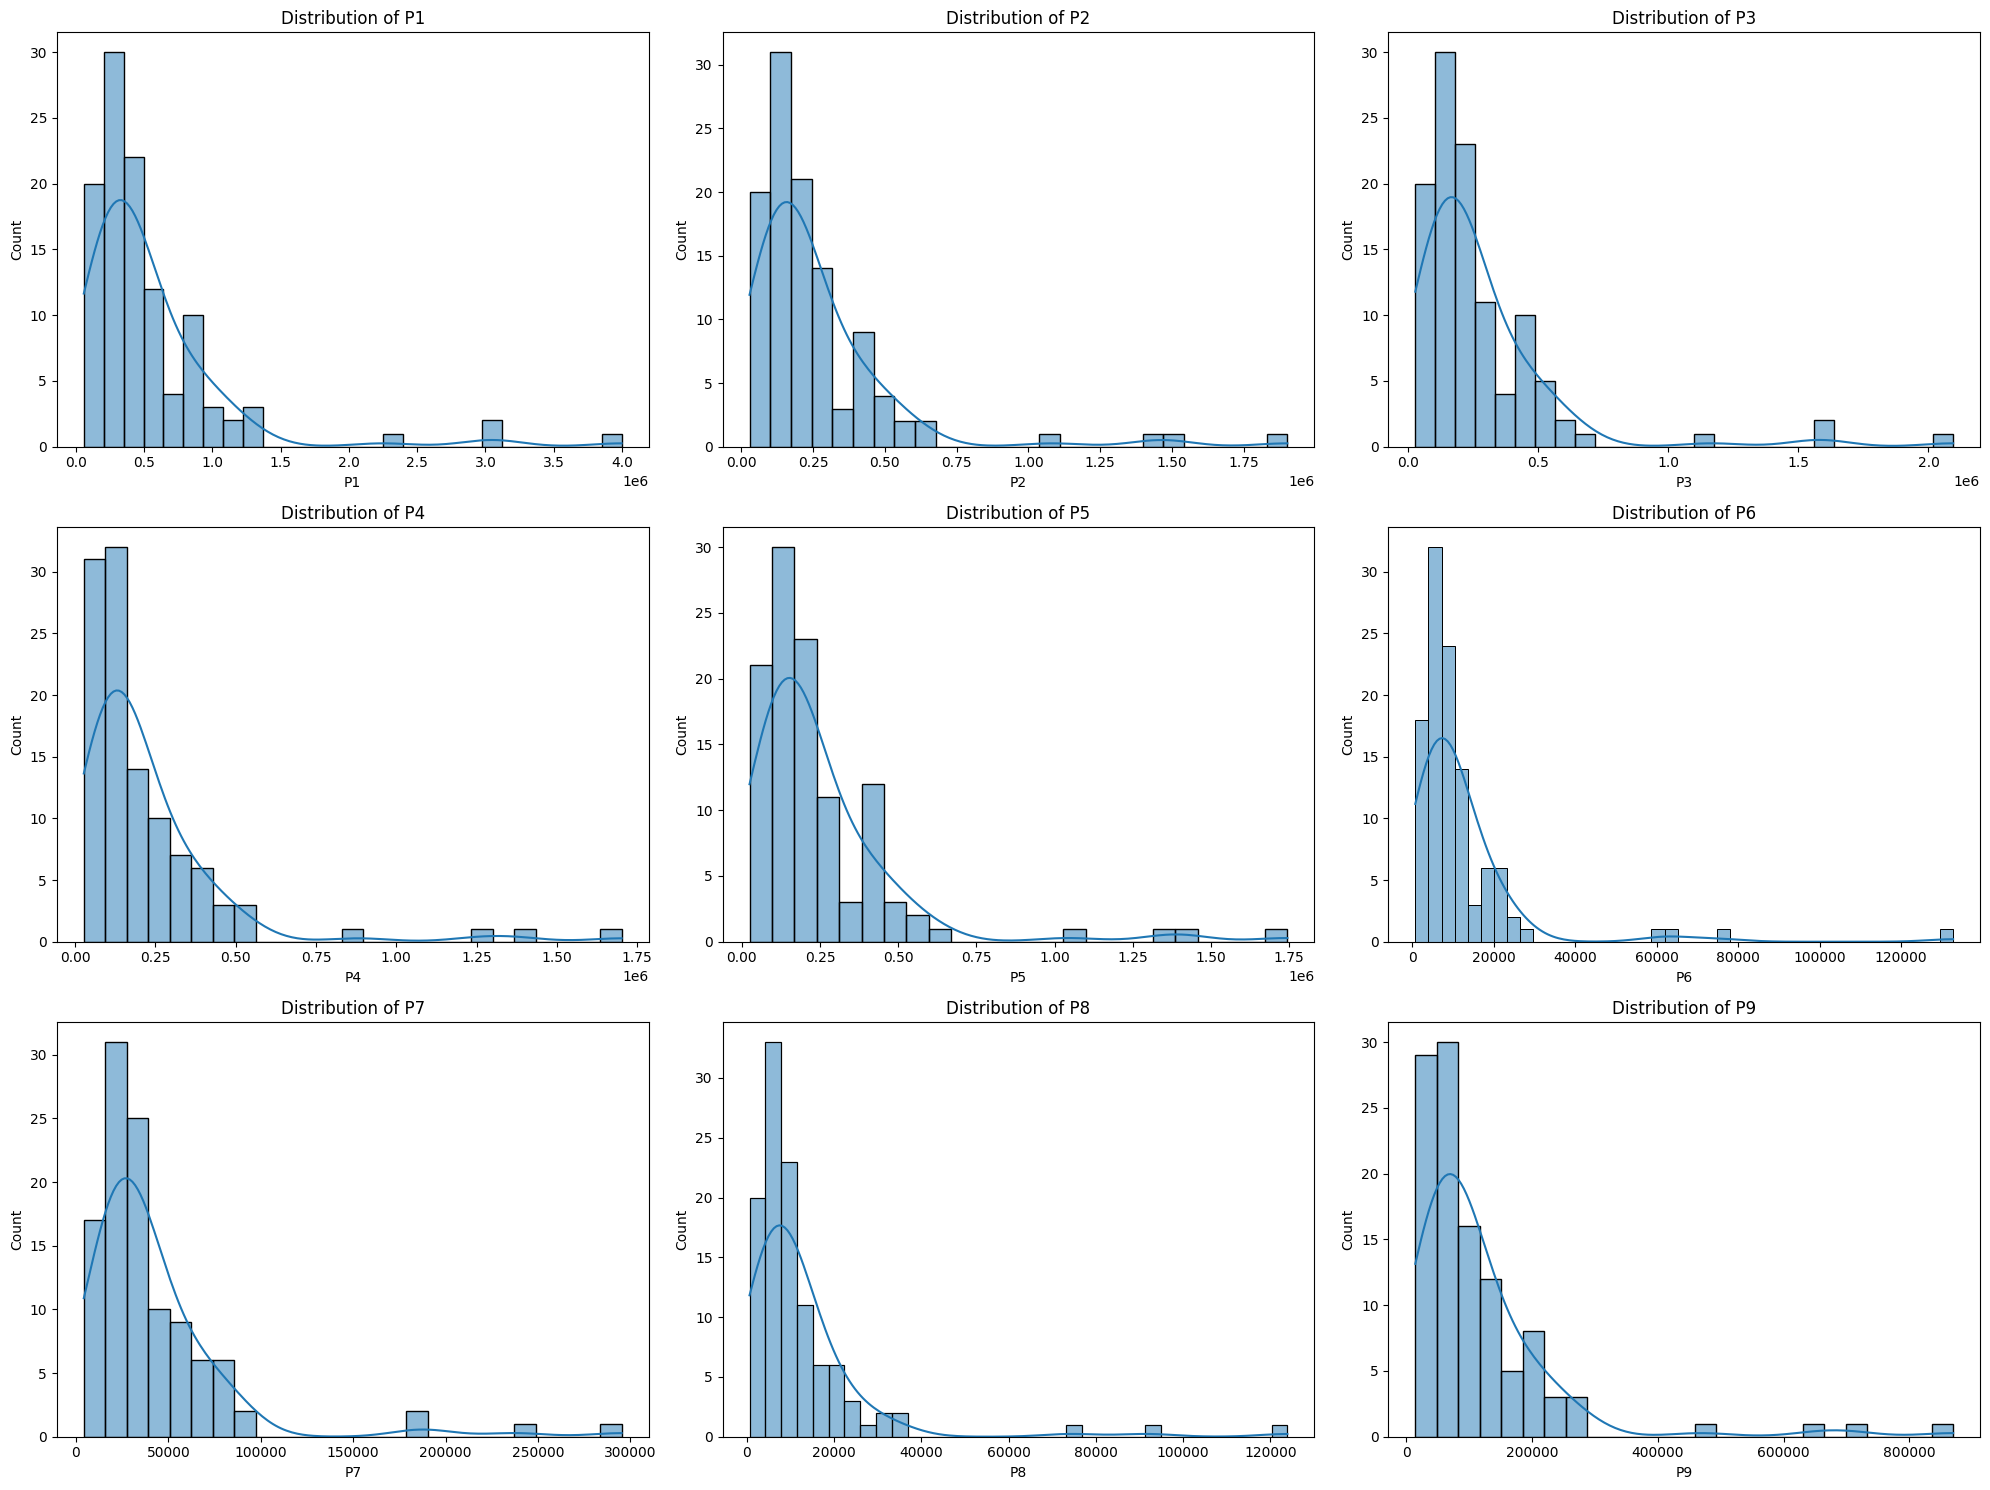

In [31]:
plt.figure(figsize=(20, 15))
for idx, col in enumerate(numerical_columns[:9], 1):  
    plt.subplot(3, 3, idx)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

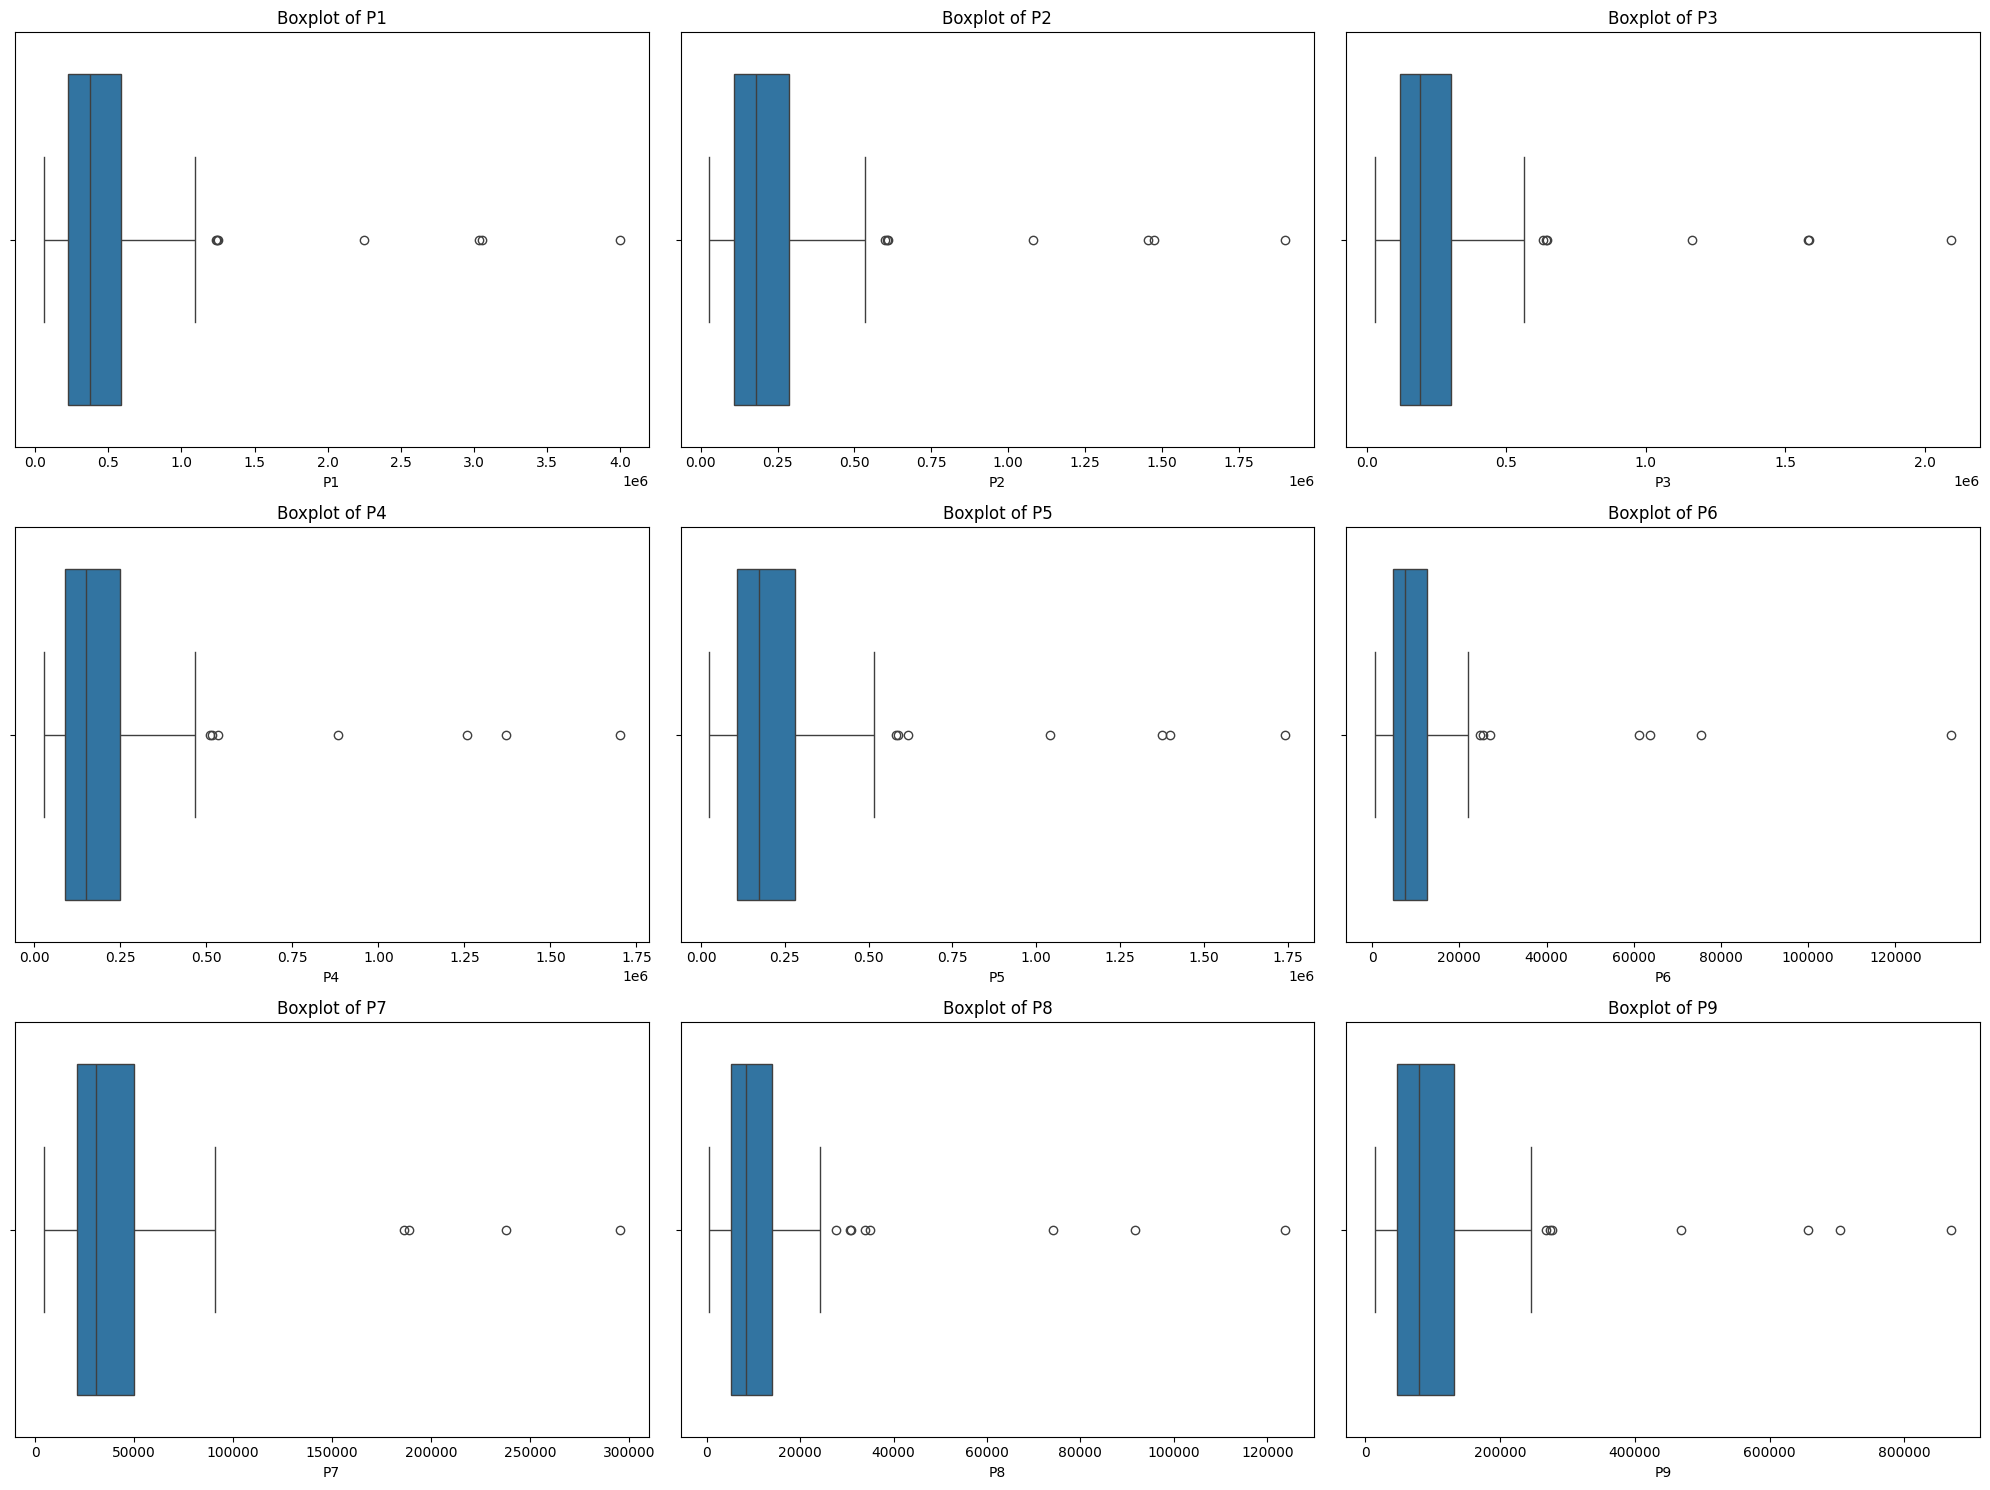

In [32]:
plt.figure(figsize=(20, 15))
for idx, col in enumerate(numerical_columns[:9], 1):  
    plt.subplot(3, 3, idx)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

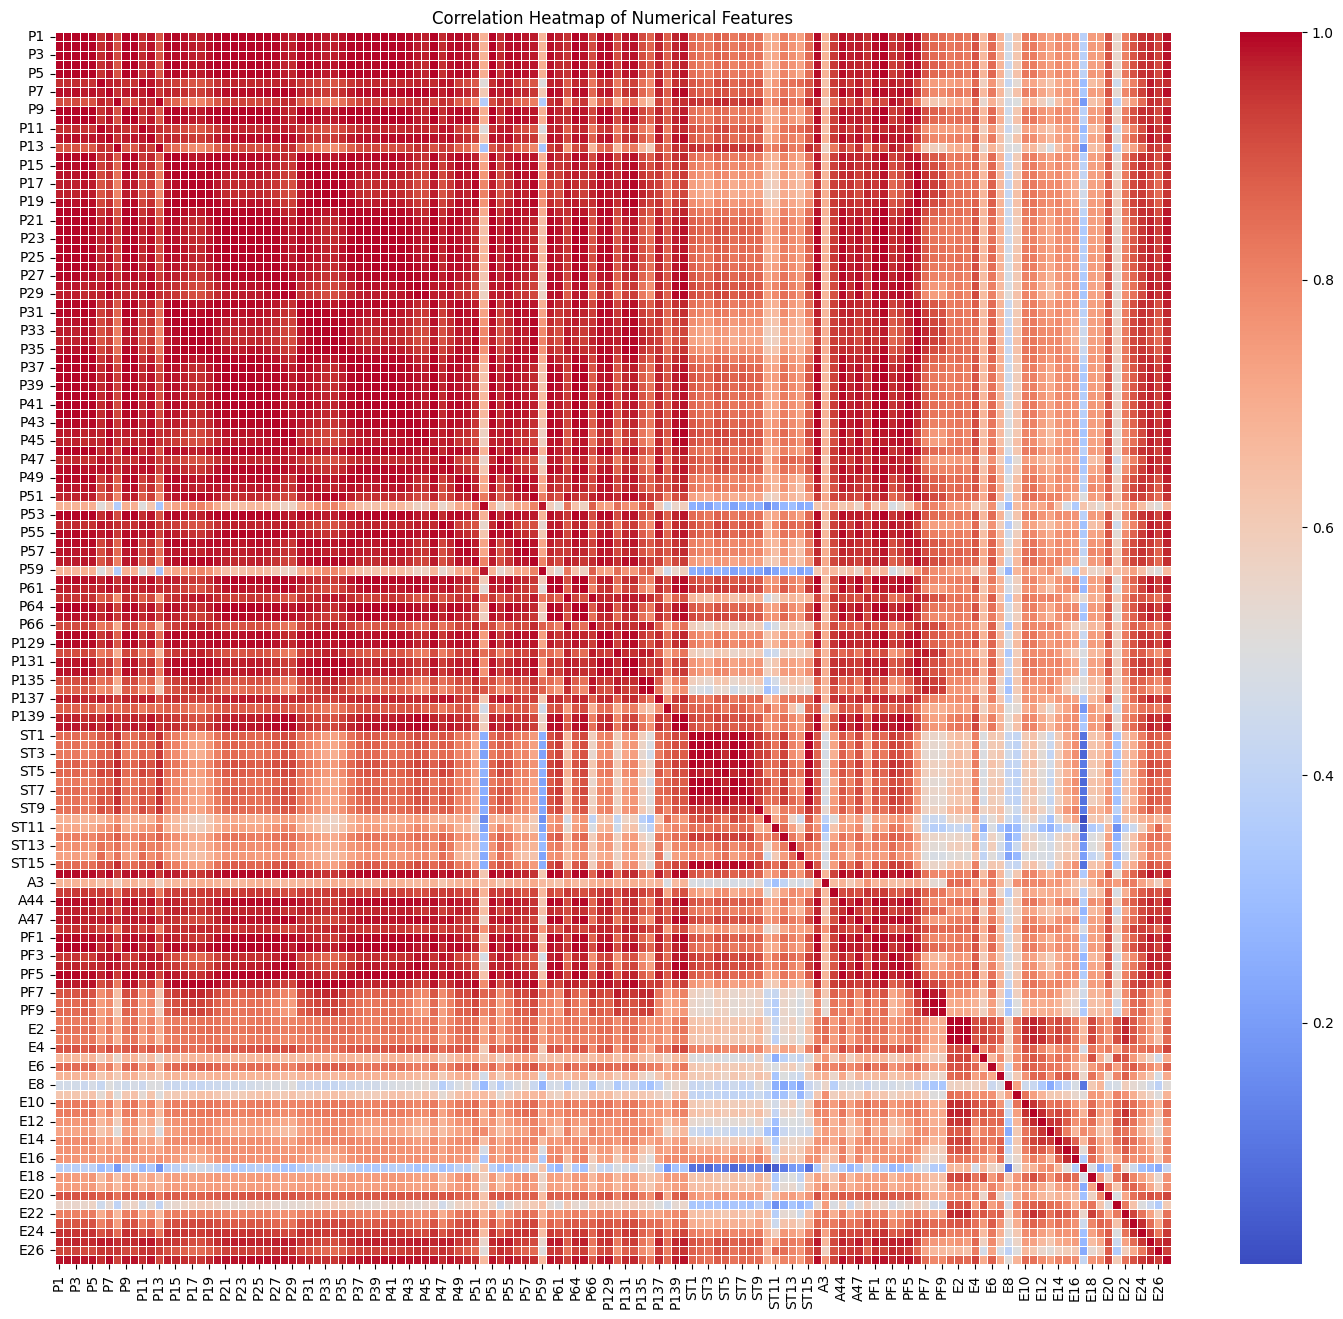

In [33]:
plt.figure(figsize=(18, 16))
corr_matrix = df[numerical_columns].corr()
sns.heatmap(corr_matrix, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [34]:
def find_outliers_IQR(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers

In [35]:
for col in numerical_columns[:5]:  
    outliers = find_outliers_IQR(df, col)
    print(f"\nOutliers in {col}: {outliers.shape[0]} found")


Outliers in P1: 7 found

Outliers in P2: 7 found

Outliers in P3: 7 found

Outliers in P4: 7 found

Outliers in P5: 7 found


In [36]:
def detect_outliers_IQR(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower) | (df[column] > upper)]
    return outliers

In [37]:
for col in df.select_dtypes(include=['int64', 'float64']).columns[:5]:
    outliers_iqr = detect_outliers_IQR(df, col)
    print(f"Column {col}: {len(outliers_iqr)} outliers detected by IQR.")

Column P1: 7 outliers detected by IQR.
Column P2: 7 outliers detected by IQR.
Column P3: 7 outliers detected by IQR.
Column P4: 7 outliers detected by IQR.
Column P5: 7 outliers detected by IQR.


In [38]:
z_scores = np.abs(zscore(df.select_dtypes(include=['int64', 'float64'])))
outliers_zscore = (z_scores > 3)
print("\nTotal Outliers Detected by Z-Score (>3):", np.sum(outliers_zscore))


Total Outliers Detected by Z-Score (>3): P1     3
P2     3
P3     3
P4     3
P5     4
      ..
E23    2
E24    2
E25    4
E26    3
E27    4
Length: 134, dtype: int64


In [39]:
print("\nChecking for Low Variance Features")

selector = VarianceThreshold(threshold=0.01)  
selector.fit(df.select_dtypes(include=['int64', 'float64']))
low_variance_features = df.select_dtypes(include=['int64', 'float64']).columns[~selector.get_support()]
print(f"\nLow Variance Features (likely useless for PCA): {list(low_variance_features)}")


Checking for Low Variance Features

Low Variance Features (likely useless for PCA): []


In [40]:
features = df.drop(columns=['PROVINCIA'])

In [41]:
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

In [42]:
pca = PCA()
pca_components = pca.fit_transform(features_scaled)

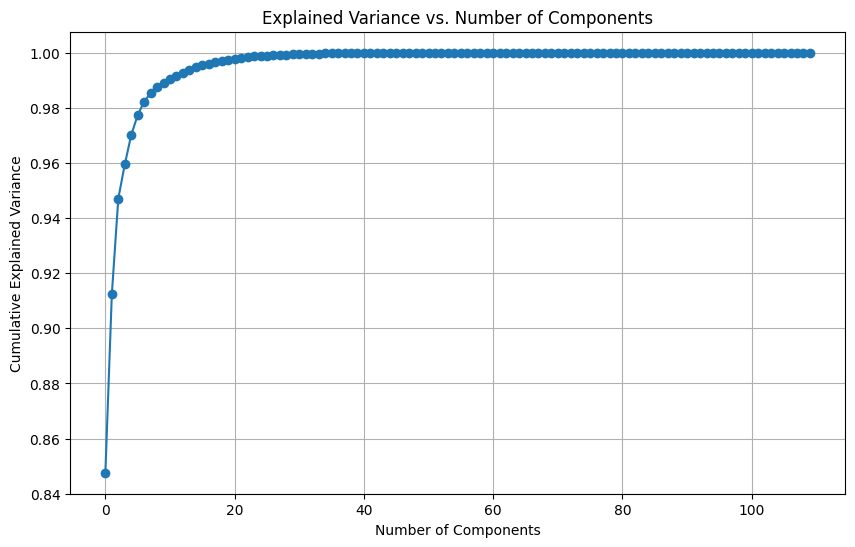

In [43]:
plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs. Number of Components')
plt.grid(True)
plt.show()

In [44]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1
print(f"\nNumber of Components to retain at least 90% variance: {n_components_90}")


Number of Components to retain at least 90% variance: 2


In [45]:
pca_columns = [f'PC{i+1}' for i in range(pca_components.shape[1])]
pca_df = pd.DataFrame(pca_components, columns=pca_columns)
pca_df['PROVINCIA'] = df['PROVINCIA']
print("\nPCA Components (first 5 rows):")
pca_df.head()


PCA Components (first 5 rows):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC102,PC103,PC104,PC105,PC106,PC107,PC108,PC109,PC110,PROVINCIA
0,-1.485062,0.310847,-1.989414,-1.678203,2.270369,0.001118,-1.682437,0.487054,0.444731,-0.509176,...,-0.000137,0.000836,0.000129,0.000208,0.000027,0.000213,0.000007,0.000035,9.228003e-16,Alessandria
1,-6.083884,1.208581,0.180026,-0.690657,0.970191,-0.047016,-1.067671,0.480486,0.225617,-0.380382,...,0.000201,-0.000499,-0.000208,-0.000055,-0.000076,-0.000164,0.000017,-0.000026,9.228003e-16,Asti
2,-7.066918,1.179719,0.833075,-0.512189,0.728506,0.029526,-0.436376,-0.076885,0.099499,-0.399824,...,0.000256,-0.000331,-0.000479,-0.000139,-0.000322,-0.000297,-0.000068,-0.000016,9.228003e-16,Biella
3,2.328681,-0.740625,-4.208404,-2.294953,1.387052,-0.823028,-0.757348,-0.002854,0.227641,-0.656894,...,0.000245,0.000320,0.000148,-0.000069,0.000148,-0.000059,0.000004,-0.000033,9.228003e-16,Cuneo
4,-3.302949,1.286667,-0.092877,-0.288182,-0.208171,-0.035011,-0.133005,-0.031438,-0.293236,-0.276812,...,-0.000162,0.000313,0.000056,-0.000481,0.000421,0.000298,0.000050,-0.000009,9.228003e-16,Novara


In [46]:
pca_subset = pca_df[['PC1', 'PC2', 'PROVINCIA']]

In [47]:
features = pca_subset[['PC1', 'PC2']].values
similarity_matrix = cosine_similarity(features)

In [48]:
G = nx.Graph()

In [49]:
for idx, row in pca_subset.iterrows():
    G.add_node(row['PROVINCIA'], PC1=row['PC1'], PC2=row['PC2'])

In [50]:
threshold = 0.90 
for i in range(similarity_matrix.shape[0]):
    for j in range(i + 1, similarity_matrix.shape[1]):
        if similarity_matrix[i, j] > threshold:
            G.add_edge(pca_subset.iloc[i]['PROVINCIA'],
                       pca_subset.iloc[j]['PROVINCIA'],
                       weight=similarity_matrix[i, j])

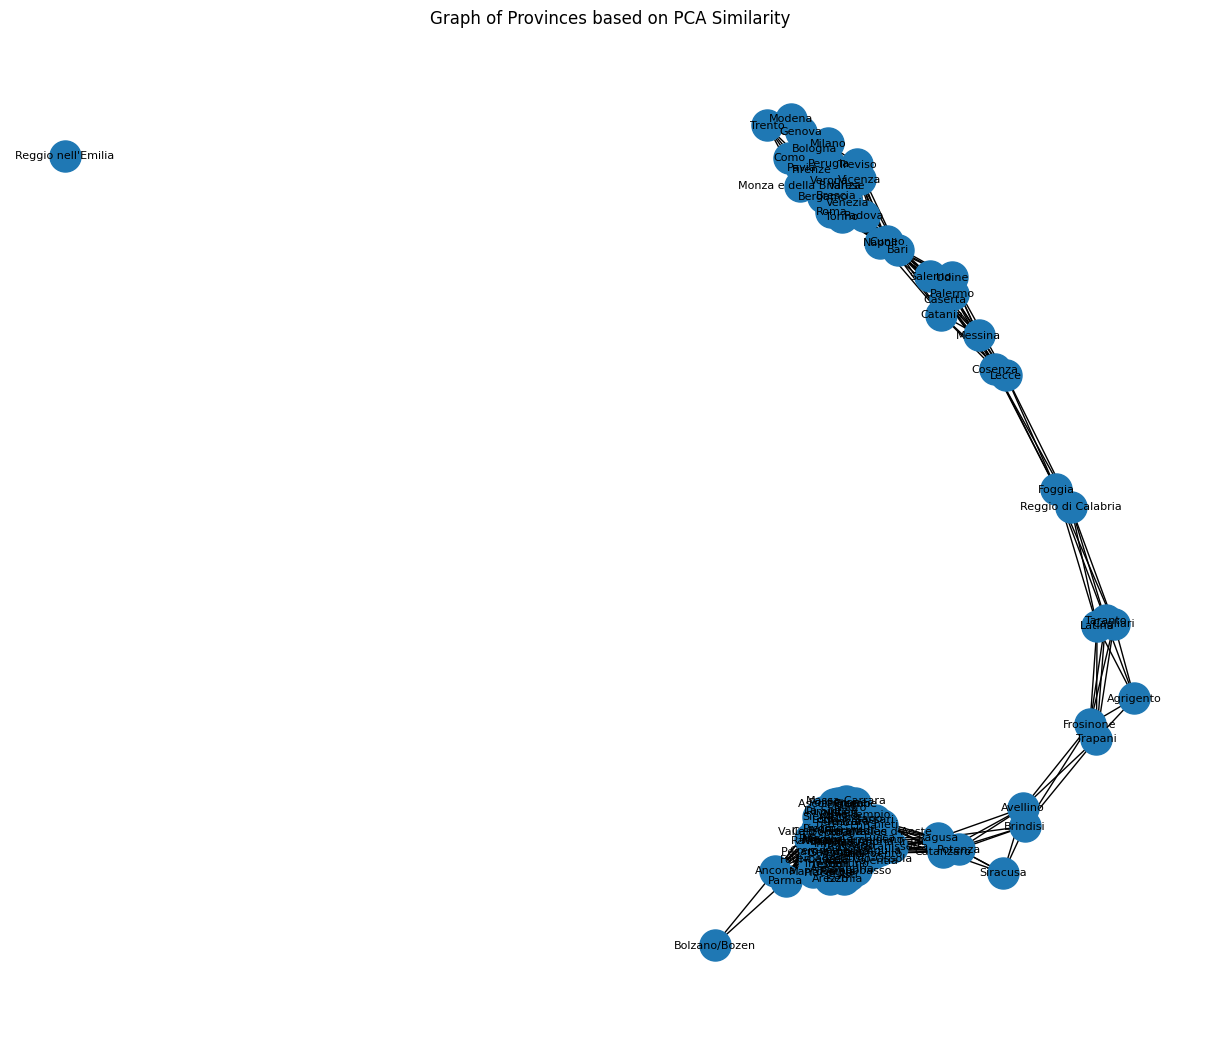

In [51]:
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42) 
nx.draw(G, pos, with_labels=True, node_size=500, font_size=8)
plt.title("Graph of Provinces based on PCA Similarity")
plt.show()

In [52]:
eigen_centrality = nx.eigenvector_centrality(G, max_iter=1000, weight='weight')
eigen_df = pd.DataFrame.from_dict(eigen_centrality, orient='index', columns=['EigenvectorCentrality'])

In [53]:
k_core = nx.core_number(G)
kcore_df = pd.DataFrame.from_dict(k_core, orient='index', columns=['Kshell'])

In [54]:
jaccard_edges = list(nx.jaccard_coefficient(G))

In [55]:
jaccard_df = pd.DataFrame(jaccard_edges, columns=['Node1', 'Node2', 'JaccardCoefficient'])

In [56]:
features = pca_subset[['PC1', 'PC2']].set_index(pca_subset['PROVINCIA'])
cosine_sim_matrix = cosine_similarity(features)
cosine_sim_df = pd.DataFrame(cosine_sim_matrix, index=features.index, columns=features.index)

In [57]:
cosine_sim_pairs = []
threshold = 0.90
for i in range(cosine_sim_df.shape[0]):
    for j in range(i+1, cosine_sim_df.shape[1]):
        if cosine_sim_df.iloc[i,j] > threshold:
            cosine_sim_pairs.append((cosine_sim_df.index[i], cosine_sim_df.index[j], cosine_sim_df.iloc[i,j]))

cosine_sim_df_pairs = pd.DataFrame(cosine_sim_pairs, columns=['Node1', 'Node2', 'CosineSimilarity'])

In [58]:
node_metrics = eigen_df.merge(kcore_df, left_index=True, right_index=True)

In [59]:
print("\nNode Metrics (first 5 rows):")
node_metrics.head()


Node Metrics (first 5 rows):


,EigenvectorCentrality,Kshell
Alessandria,1.366330e-01,48
Asti,1.366706e-01,48
Biella,1.366977e-01,48
Cuneo,8.672509e-07,11
Novara,1.261019e-01,48


In [60]:
print("\nSample Jaccard Coefficients (first 5 rows):")
jaccard_df.head()


Sample Jaccard Coefficients (first 5 rows):


,Node1,Node2,JaccardCoefficient
0,Napoli,Valle d'Aosta/Vallée d'Aoste,0.0
1,Napoli,Lecco,0.0
2,Napoli,Pordenone,0.0
3,Napoli,L'Aquila,0.0
4,Napoli,Pescara,0.0


In [61]:
print("\nSample Cosine Similarity (Top pairs):")
cosine_sim_df_pairs.head()


Sample Cosine Similarity (Top pairs):


,Node1,Node2,CosineSimilarity
0,Alessandria,Asti,0.999948
1,Alessandria,Biella,0.999163
2,Alessandria,Novara,0.986397
3,Alessandria,Verbano-Cusio-Ossola,0.996349
4,Alessandria,Vercelli,0.999855


In [62]:
node_metrics['CombinedScore'] = (
    (node_metrics['EigenvectorCentrality'] / node_metrics['EigenvectorCentrality'].max()) + 
    (node_metrics['Kshell'] / node_metrics['Kshell'].max())
) / 2

In [63]:
top_hotspots = node_metrics.sort_values(by='CombinedScore', ascending=False).head(10)

print("\nTop 10 Influential Hotspots based on Combined Score:")
print(top_hotspots)


Top 10 Influential Hotspots based on Combined Score:
                              EigenvectorCentrality  Kshell  CombinedScore
Valle d'Aosta/Vallée d'Aoste               0.137640      48       1.000000
Pescara                                    0.137640      48       0.999999
Ogliastra                                  0.137568      48       0.999736
Massa-Carrara                              0.137567      48       0.999733
Verbano-Cusio-Ossola                       0.137495      48       0.999471
Isernia                                    0.137493      48       0.999466
Rovigo                                     0.137322      48       0.998842
Belluno                                    0.137251      48       0.998585
Teramo                                     0.137209      48       0.998433
Viterbo                                    0.136698      48       0.996578


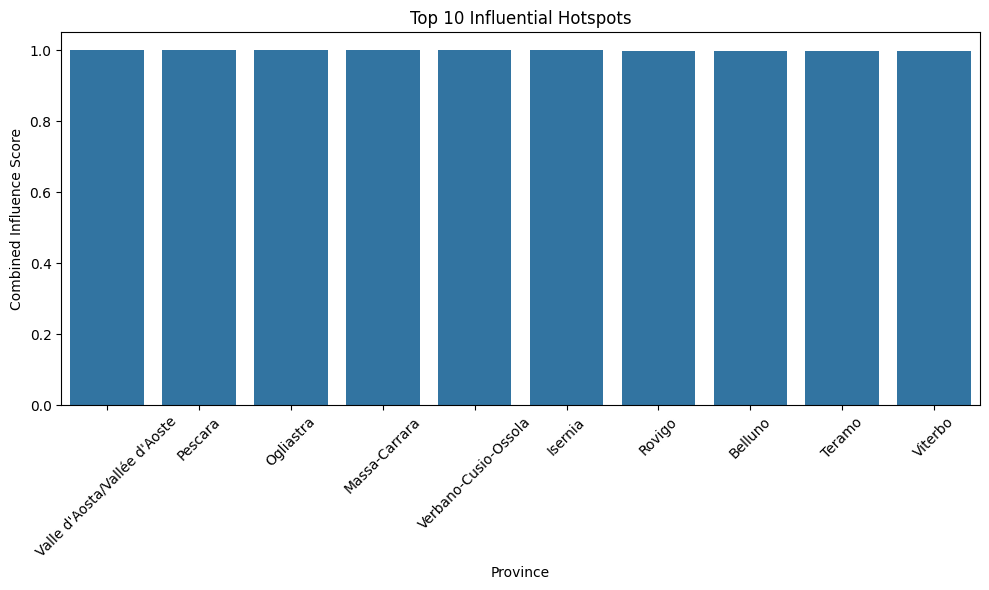

In [64]:
plt.figure(figsize=(10,6))
sns.barplot(x=top_hotspots.index, y=top_hotspots['CombinedScore'])
plt.xticks(rotation=45)
plt.title('Top 10 Influential Hotspots')
plt.ylabel('Combined Influence Score')
plt.xlabel('Province')
plt.tight_layout()
plt.show()

In [65]:
top_hotspot_nodes = top_hotspots.index.tolist()

In [66]:
node_colors = []
for node in G.nodes():
    if node in top_hotspot_nodes:
        node_colors.append('red')  
    else:
        node_colors.append('lightblue')  

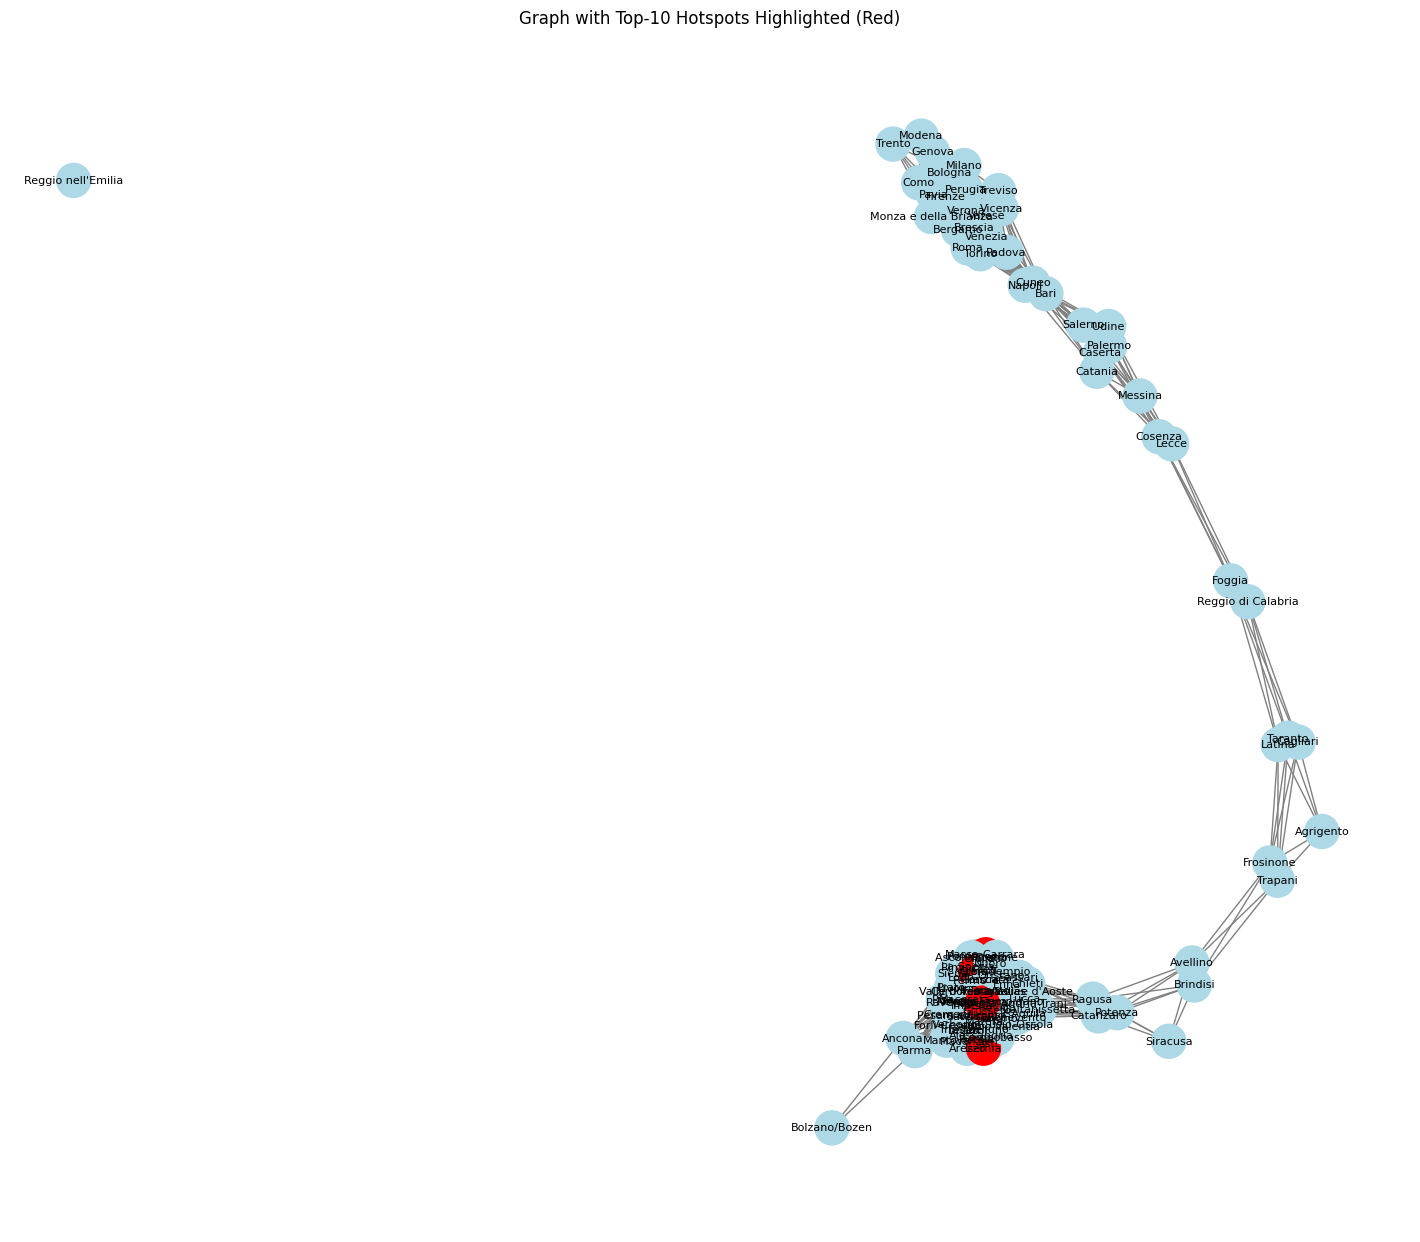

In [67]:
plt.figure(figsize=(14, 12))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, 
        with_labels=True, 
        node_color=node_colors, 
        node_size=600, 
        font_size=8, 
        edge_color='gray')
plt.title("Graph with Top-10 Hotspots Highlighted (Red)")
plt.show()

In [68]:
top_hotspots.reset_index(inplace=True)  
top_hotspots.rename(columns={'index': 'Province'}, inplace=True)
output_file = "Top10_Hotspots.csv"
top_hotspots.to_csv(output_file, index=False)

print(f"\nTop-10 Hotspots saved successfully to {output_file}!")


Top-10 Hotspots saved successfully to Top10_Hotspots.csv!


In [69]:
full_metrics_file = "All_Province_Node_Metrics.csv"
node_metrics.to_csv(full_metrics_file)
print(f"All node metrics saved successfully to {full_metrics_file}!")

All node metrics saved successfully to All_Province_Node_Metrics.csv!


In [70]:
node_metrics

,EigenvectorCentrality,Kshell,CombinedScore
Alessandria,1.366330e-01,48,0.996340
Asti,1.366706e-01,48,0.996477
Biella,1.366977e-01,48,0.996575
Cuneo,8.672509e-07,11,0.114586
Novara,1.261019e-01,48,0.958085
...,...,...,...
Nuoro,1.349313e-01,48,0.990159
Ogliastra,1.375678e-01,48,0.999736
Olbia-Tempio,1.347028e-01,48,0.989329
Oristano,1.277848e-01,48,0.964198


In [ ]:
# your existing code above...

# 👇 ADD THIS AT THE END

print("="*60)
print("   CITY HOTSPOT IDENTIFICATION SYSTEM")
print("="*60)

print("\n📊 DATASET SUMMARY")
print("-"*40)
print(f"Total Cities: {df.shape[0]}")
print(f"Total Features: {df.shape[1]}")
print(f"Missing Values: {df.isnull().sum().sum()}")

print("\n🏆 TOP 10 HOTSPOTS")
print("-"*60)
print(df.head(10))

top_city = df.iloc[0]

print("\n🔥 MOST INFLUENTIAL CITY")
print("-"*40)
print(f"City Name: {top_city.name}")
print(f"Score: {top_city['CombinedScore']:.4f}")
